In [23]:

import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import brentq

c = 299792458.0

The following code was **entirely** genrated by Chat GPT. I provided 3 articles: "","" and . The prompt was the following: .

The markdowns (text) will be mine, as I try to reason what he made.

1. Define the ordinary refractive index and extraordinary refractive index based on wavelength using Sellmeier equations.

This can be substituted if we have the index of refraction of the crystal given by the manufacturer's.

In [24]:
# ============================================================
# BBO Sellmeier equations
# wavelength input in meters
# ============================================================

def n_o_BBO(lam):
    """
    Ordinary refractive index of BBO.
    lam in meters.
    """
    l = lam * 1e6  # micrometers

    return np.sqrt(
        2.7359
        + 0.01878 / (l**2 - 0.01822)
        - 0.01354 * l**2
    )


def n_e_BBO(lam):
    """
    Principal extraordinary refractive index of BBO.
    lam in meters.
    """
    l = lam * 1e6

    return np.sqrt(
        2.3753
        + 0.01224 / (l**2 - 0.01667)
        - 0.01516 * l**2
    )


def n_e_eff_BBO(lam, theta):
    """
    Effective extraordinary refractive index.

    theta = angle between propagation direction
            and optical axis, in radians.
    """

    no = n_o_BBO(lam)
    ne = n_e_BBO(lam)

    return 1 / np.sqrt(
        np.cos(theta)**2 / no**2
        + np.sin(theta)**2 / ne**2
    )

**Substitute here!**

In [25]:
# ============================================================
# Schwaller experimental parameters
# ============================================================

L = 3e-3

lambda_p = 404e-9
lambda_deg = 808e-9

# Approximate 10-nm BPF window
lambda_min = 803e-9
lambda_max = 813e-9

brentq is a numerical root-finding function in Python's SciPy library that finds a zero of a continuous function within a sign-changing interval [a, b]. The goal is to find the phase matching angle using:
$$
k_p = 2k_c → n_{e_{eff}}(\lambda_c, \theta_p) = n_p(\lambda_p)
$$

Where

$$
n_{e_{eff}} = \frac{1}{\sqrt{
        \cos(\theta)^2 / n_o^2
        + \sin(\theta)^2 / n_e^2}}
$$


In [26]:
# ============================================================
# Find the BBO phase-matching angle for 404 -> 808 + 808 nm
# ============================================================

target_n = n_o_BBO(lambda_deg)

theta_pm = brentq(
    lambda th:
        n_e_eff_BBO(lambda_p, th) - target_n,
    1e-8,
    np.pi/2 - 1e-8
)
###
###

print("Phase-matching angle =",
      np.degrees(theta_pm), "degrees")

Phase-matching angle = 28.88727042644851 degrees


Calculating the waist $w_c$ and $w_p$ from $Z_{R_P}/L$ and $Z_{R_C}/L$.

In [27]:
# ============================================================
# Focusing parameters -> physical waists
# ============================================================

def central_wavenumbers():

    kp = (
        2 * np.pi
        * n_e_eff_BBO(lambda_p, theta_pm)
        / lambda_p
    )

    kc = (
        2 * np.pi
        * n_o_BBO(lambda_deg)
        / lambda_deg
    )

    return kp, kc


def waists_from_ZR_ratios(ZRp_over_L, ZRc_over_L):
    """
    Returns physical pump and collection waists inside crystal.
    """

    kp, kc = central_wavenumbers()

    ZRp = ZRp_over_L * L
    ZRc = ZRc_over_L * L

    wp = np.sqrt(2 * ZRp / kp)
    wc = np.sqrt(2 * ZRc / kc)

    return wp, wc

In [28]:
wp, wc = waists_from_ZR_ratios(
    ZRp_over_L=8,
    ZRc_over_L=1
)

print("wp =", wp * 1e6, "um")
print("wc =", wc * 1e6, "um")

wp = 43.11475238329462 um
wc = 21.55737619164731 um


Energy conservation


In [29]:
def lambda_idler(lambda_signal):

    return 1.0 / (
        1.0/lambda_p
        - 1.0/lambda_signal
    )

Calculating optical parameter's. Bennink doens't explicitly assume degeneracy, even though Schwaller does. Here the code doesn't assume it also.

In [30]:
def optical_parameters(lambda_s,
                       ZRp_over_L,
                       ZRc_over_L):

    lambda_i = lambda_idler(lambda_s)

    wp, wc = waists_from_ZR_ratios(
        ZRp_over_L,
        ZRc_over_L
    )

    kp = (
        2*np.pi
        * n_e_eff_BBO(lambda_p, theta_pm)
        / lambda_p
    )

    ks = (
        2*np.pi
        * n_o_BBO(lambda_s)
        / lambda_s
    )

    ki = (
        2*np.pi
        * n_o_BBO(lambda_i)
        / lambda_i
    )

    xi_p = L / (kp * wp**2)
    xi_s = L / (ks * wc**2)
    xi_i = L / (ki * wc**2)

    # BBO: no periodic poling term
    Delta_k = kp - ks - ki

    return (
        lambda_i,
        kp, ks, ki,
        xi_p, xi_s, xi_i,
        Delta_k
    )

Here we start to get closer to defining the ration $P_s(0)/P_s(\infty)$ by defining the wave-functions. He assumes the signal is in a fundamental Gaussian collection mode, whereas the idler is in a radial mode $n$ in the Laguerre-Gaussian mode. He calculates the overlap between these two functions ($\cal{O}_n$) and from this get's the $\psi_n(\omega_i, \omega_s)$.

In [31]:
# ============================================================
# Bennink radial-mode amplitude
# ============================================================

def bennink_amplitude(
    lambda_s,
    ZRp_over_L,
    ZRc_over_L,
    n_mode,
    N_l=401
):

    (
        lambda_i,
        kp, ks, ki,
        xi_p, xi_s, xi_i,
        Delta_k
    ) = optical_parameters(
        lambda_s,
        ZRp_over_L,
        ZRc_over_L
    )

    # Dimensionless phase mismatch
    Phi = Delta_k * L

    # Bennink auxiliary quantities
    A_plus = (
        1
        + ks * xi_s / (kp * xi_p)
        + ki * xi_i / (kp * xi_p)
    )

    A_minus = (
        1
        + ks * xi_s / (kp * xi_p)
        - ki * xi_i / (kp * xi_p)
    )

    B_prefactor = 1 - Delta_k / kp

    B_plus = B_prefactor * (
        1
        + ((ks + Delta_k) / (kp - Delta_k))
          * (xi_p / xi_s)
        + ((ki + Delta_k) / (kp - Delta_k))
          * (xi_p / xi_i)
    )

    B_minus = B_prefactor * (
        1
        + ((ks + Delta_k) / (kp - Delta_k))
          * (xi_p / xi_s)
        - ((ki + Delta_k) / (kp - Delta_k))
          * (xi_p / xi_i)
    )

    gamma = xi_s * xi_i / xi_p

    # Dimensionless crystal coordinate l in [-1,1]
    ell = np.linspace(-1, 1, N_l)

    denominator = (
        A_plus
        - 1j * ell * B_plus * gamma
    )

    radial_factor = (
        (
            A_minus
            + 1j * ell * B_minus * gamma
        )
        / denominator
    )**n_mode

    integrand = (
        np.exp(1j * Phi * ell / 2)
        / denominator
        * radial_factor
    )

    longitudinal_integral = np.trapezoid(
        integrand,
        ell
    )

    # Relative prefactor from Bennink Eq. (48).
    # Overall constants cancel in eta_c.
    prefactor = np.sqrt(
        (ks * ki / kp)
        * (xi_s * xi_i / xi_p)
    )

    return prefactor * longitudinal_integral

Here we finally calculate the integral.

In [32]:
# ============================================================
# Spectrally integrated radial-mode probabilities
# ============================================================

def radial_mode_probabilities(
    ZRp_over_L,
    ZRc_over_L,
    n_max=20,
    N_lambda=81,
    N_l=301
):

    lambda_s_array = np.linspace(
        lambda_min,
        lambda_max,
        N_lambda
    )

    spectral_weights = np.zeros(
        (n_max + 1, N_lambda)
    )

    for j, lambda_s in enumerate(lambda_s_array):

        lambda_i = lambda_idler(lambda_s)

        # d omega / d lambda
        jacobian = (
            2 * np.pi * c
            / lambda_s**2
        )

        for n in range(n_max + 1):

            amp = bennink_amplitude(
                lambda_s,
                ZRp_over_L,
                ZRc_over_L,
                n_mode=n,
                N_l=N_l
            )

            # Relative weight from Bennink Eq. (5)
            spectral_weights[n, j] = (
                np.abs(amp)**2
                / (lambda_s * lambda_i)
                * jacobian
            )

    P_n = np.trapezoid(
        spectral_weights,
        lambda_s_array,
        axis=1
    )

    return P_n

In [33]:
def eta_c_theory(
    ZRp_over_L,
    ZRc_over_L,
    n_max=20,
    N_lambda=81,
    N_l=301
):

    P_n = radial_mode_probabilities(
        ZRp_over_L,
        ZRc_over_L,
        n_max=n_max,
        N_lambda=N_lambda,
        N_l=N_l
    )

    return P_n[0] / np.sum(P_n)

In [34]:
eta = eta_c_theory(
    ZRp_over_L=8.8,
    ZRc_over_L=1.0
)

print("eta_c =", eta)

eta_c = 0.9959296964827575


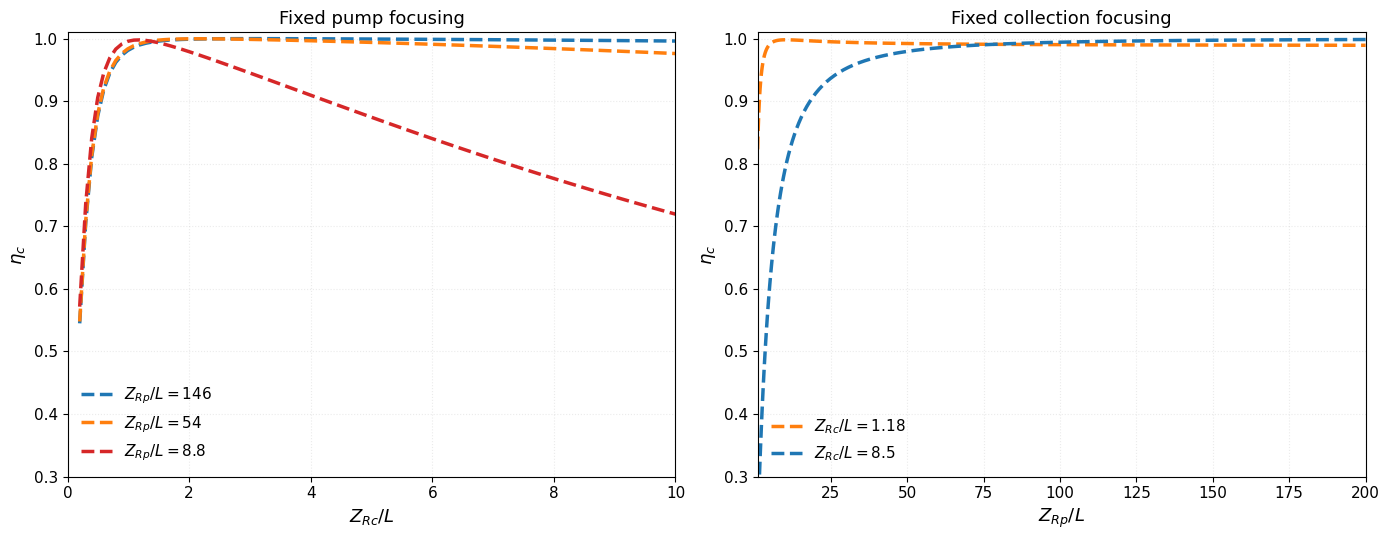

In [42]:
# ============================================================
# THEORETICAL eta_c CURVES
# Similar to Schwaller Figs. 4 and 6
#
# LEFT:
#   Fixed Z_Rp/L, varying Z_Rc/L
#
# RIGHT:
#   Fixed Z_Rc/L, varying Z_Rp/L
# ============================================================


# ------------------------------------------------------------
# Numerical calculation parameters
# ------------------------------------------------------------

n_max = 15
N_lambda = 51
N_l = 251


# ============================================================
# FIGURE
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5.5)
)


# ============================================================
# LEFT PANEL
# eta_c versus collection focusing
# Fixed pump Rayleigh ranges
# ============================================================

ZRp_values_fixed = [
    146,
    54,
    8.8
]

ZRc_values = np.linspace(
    0.2,
    10,
    100
)

colors_left = [
    "tab:blue",
    "tab:orange",
    "tab:red"
]


for ZRp, color in zip(
    ZRp_values_fixed,
    colors_left
):

    eta_values = []

    for ZRc in ZRc_values:

        eta = eta_c_theory(
            ZRp_over_L=ZRp,
            ZRc_over_L=ZRc,
            n_max=n_max,
            N_lambda=N_lambda,
            N_l=N_l
        )

        eta_values.append(eta)

    axes[0].plot(
        ZRc_values,
        eta_values,
        linestyle="--",
        linewidth=2.5,
        color=color,
        label=fr"$Z_{{Rp}}/L={ZRp}$"
    )


axes[0].set_xlabel(
    r"$Z_{Rc}/L$",
    fontsize=13
)

axes[0].set_ylabel(
    r"$\eta_c$",
    fontsize=13
)

axes[0].set_xlim(
    0,
    10
)

axes[0].set_ylim(
    0.3,
    1.01
)

axes[0].tick_params(
    axis="both",
    labelsize=11
)

axes[0].legend(
    fontsize=11,
    frameon=False
)

axes[0].grid(
    alpha=0.25,
    linestyle=":"
)

axes[0].set_title(
    "Fixed pump focusing",
    fontsize=13
)


# ============================================================
# RIGHT PANEL
# eta_c versus pump focusing
# Fixed collection Rayleigh ranges
# ============================================================

ZRc_values_fixed = [
    1.18,
    8.5
]

ZRp_values = np.geomspace(
    1,
    200,
    100
)

colors_right = [
    "tab:orange",
    "tab:blue"
]


for ZRc, color in zip(
    ZRc_values_fixed,
    colors_right
):

    eta_values = []

    for ZRp in ZRp_values:

        eta = eta_c_theory(
            ZRp_over_L=ZRp,
            ZRc_over_L=ZRc,
            n_max=n_max,
            N_lambda=N_lambda,
            N_l=N_l
        )

        eta_values.append(eta)

    axes[1].plot(
        ZRp_values,
        eta_values,
        linestyle="--",
        linewidth=2.5,
        color=color,
        label=fr"$Z_{{Rc}}/L={ZRc}$"
    )


axes[1].set_xlabel(
    r"$Z_{Rp}/L$",
    fontsize=13
)

axes[1].set_ylabel(
    r"$\eta_c$",
    fontsize=13
)


axes[1].set_xlim(
    1,
    200
)

axes[1].set_ylim(
    0.3,
    1.01
)

axes[1].tick_params(
    axis="both",
    labelsize=11
)

axes[1].legend(
    fontsize=11,
    frameon=False
)

axes[1].grid(
    alpha=0.25,
    linestyle=":"
)

axes[1].set_title(
    "Fixed collection focusing",
    fontsize=13
)


# ============================================================
# Final formatting
# ============================================================

plt.tight_layout()

plt.show()

Now let's do it for the setup in UFRJ.

In [37]:
# ============================================================
# YOUR EXPERIMENTAL PARAMETERS
# ============================================================

L = 5e-3

lambda_p = 325e-9
lambda_deg = 650e-9

# Spectral filter window
lambda_min = 649e-9
lambda_max = 652e-9


# ============================================================
# Recalculate the Type-I BBO phase-matching angle
# e -> o + o
# ============================================================

target_n = n_o_BBO(lambda_deg)

theta_pm = brentq(
    lambda th:
        n_e_eff_BBO(lambda_p, th) - target_n,
    1e-8,
    np.pi/2 - 1e-8
)
# we pass the function, the minimum angle and the maximum angle

print(
    "Phase-matching angle =",
    np.degrees(theta_pm),
    "degrees"
)

Phase-matching angle = 36.665778164128355 degrees


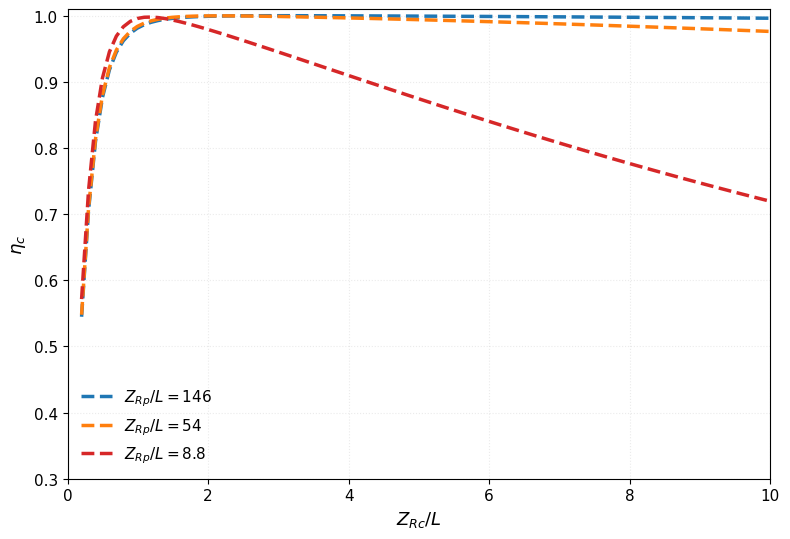

In [38]:
# ============================================================
# eta_c versus collection focusing
#
# Fixed pump Rayleigh ranges:
# Z_Rp / L = 146, 54, 8
# ============================================================

ZRp_values_fixed = [
    146,
    54,
    8.8
]

# Scan collection Rayleigh range
ZRc_values = np.linspace(
    0.2,
    10,
    100
)

colors = [
    "tab:blue",
    "tab:orange",
    "tab:red"
]


# Numerical calculation parameters
n_max = 15
N_lambda = 51
N_l = 251


plt.figure(figsize=(8, 5.5))


for ZRp, color in zip(
    ZRp_values_fixed,
    colors
):

    eta_values = []

    for ZRc in ZRc_values:

        eta = eta_c_theory(
            ZRp_over_L=ZRp,
            ZRc_over_L=ZRc,
            n_max=n_max,
            N_lambda=N_lambda,
            N_l=N_l
        )

        eta_values.append(eta)

    plt.plot(
        ZRc_values,
        eta_values,
        linestyle="--",
        linewidth=2.5,
        color=color,
        label=fr"$Z_{{Rp}}/L={ZRp}$"
    )


plt.xlabel(
    r"$Z_{Rc}/L$",
    fontsize=13
)

plt.ylabel(
    r"$\eta_c$",
    fontsize=13
)

plt.xlim(
    0,
    10
)

plt.ylim(
    0.3,
    1.01
)

plt.tick_params(
    axis="both",
    labelsize=11
)

plt.legend(
    fontsize=11,
    frameon=False
)

plt.grid(
    alpha=0.25,
    linestyle=":"
)

plt.tight_layout()

plt.show()

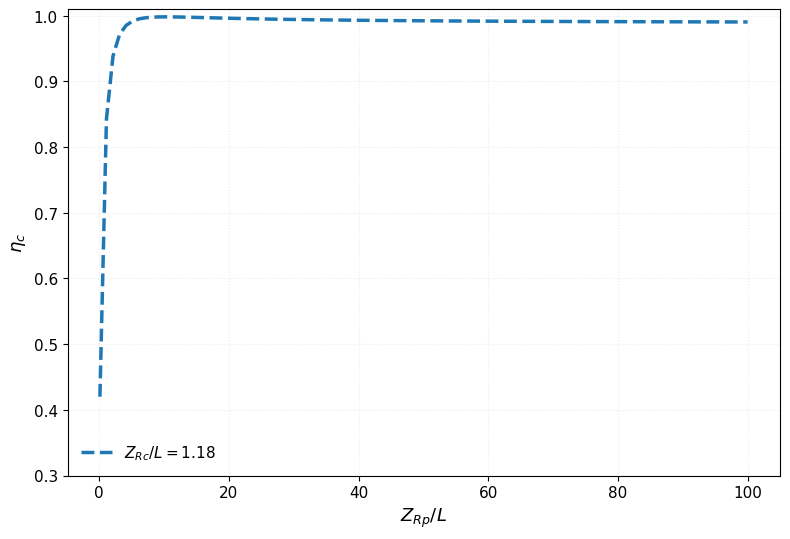

In [39]:
# ============================================================
# eta_c versus pump focusing
# Fixed collection focus: Z_Rc / L = 1.18
# ============================================================

ZRc_fixed = 1.18

ZRp_values = np.linspace(
    0.1,
    100,
    100
)

eta_values = []

for ZRp in ZRp_values:

    eta = eta_c_theory(
        ZRp_over_L=ZRp,
        ZRc_over_L=ZRc_fixed,
        n_max=15,
        N_lambda=51,
        N_l=251
    )

    eta_values.append(eta)


# ============================================================
# Plot
# ============================================================

plt.figure(figsize=(8, 5.5))

plt.plot(
    ZRp_values,
    eta_values,
    linestyle="--",
    linewidth=2.5,
    color="tab:blue",
    label=fr"$Z_{{Rc}}/L={ZRc_fixed}$"
)

plt.xlabel(
    r"$Z_{Rp}/L$",
    fontsize=13
)

plt.ylabel(
    r"$\eta_c$",
    fontsize=13
)



plt.ylim(
    0.3,
    1.01
)

plt.tick_params(
    axis="both",
    labelsize=11
)

plt.legend(
    fontsize=11,
    frameon=False
)

plt.grid(
    alpha=0.25,
    linestyle=":"
)

plt.tight_layout()

plt.show()

In [40]:
eta_values = np.array(eta_values)

idx_max = np.argmax(eta_values)

print(
    f"Maximum eta_c = {eta_values[idx_max]:.6f}"
)

print(
    f"Optimal Z_Rp/L = {ZRp_values[idx_max]:.3f}"
)

Maximum eta_c = 0.998095
Optimal Z_Rp/L = 10.191
